## MultiTemporalCrop Example

In [ ]:
!pip install git+https://github.com/IBM/terratorch.git

In [7]:
!pip install albumentations==1.3.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.7/125.7 kB 10.1 MB/s eta 0:00:00
  Attempting uninstall: albumentations
    Found existing installation: albumentations 2.0.8
    Uninstalling albumentations-2.0.8:
      Successfully uninstalled albumentations-2.0.8


In [1]:
import os
import sys
import numpy as np
import torch

import terratorch
from terratorch.datamodules import MultiTemporalCropClassificationDataModule
from terratorch.tasks import SemanticSegmentationTask
from terratorch.datasets.transforms import FlattenTemporalIntoChannels, UnflattenTemporalFromChannels

import albumentations
from albumentations import Compose, Flip
from albumentations.pytorch import ToTensorV2

import lightning.pytorch as pl
from lightning.pytorch.loggers import TensorBoardLogger
from lightning.pytorch.callbacks import ModelCheckpoint

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


If you have the data already downloaded, update the `DATASET_PATH`. Otherwise, download it with the following code. Check [here](https://huggingface.co/datasets/ibm-nasa-geospatial/multi-temporal-crop-classification) for more details on this dataset.

In [2]:
DATASET_PATH = "./data"

In [15]:
from huggingface_hub import snapshot_download

repo_id = "ibm-nasa-geospatial/multi-temporal-crop-classification"
_ = snapshot_download(repo_id=repo_id, repo_type="dataset", cache_dir="./cache", local_dir=DATASET_PATH)

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

In [2]:
OUT_DIR = "./multicrop_example"  # where to save checkpoints and log files

BATCH_SIZE = 16
EPOCHS = 50
LR = 2.0e-4
WEIGHT_DECAY = 0.1
HEAD_DROPOUT=0.1
FREEZE_BACKBONE = False

BANDS = ["BLUE", "GREEN", "RED", "NIR_NARROW", "SWIR_1", "SWIR_2"]
NUM_FRAMES = 3

CLASS_WEIGHTS = [
    0.386375, 0.661126, 0.548184, 0.640482, 0.876862, 0.925186, 3.249462,
    1.542289, 2.175141, 2.272419, 3.062762, 3.626097, 1.198702
]

SEED = 0

#### Exploring the dataset

In [21]:
# Adding augmentations for a temporal dataset requires additional transforms
train_transforms = [
    terratorch.datasets.transforms.FlattenTemporalIntoChannels(),
    albumentations.Flip(),
    albumentations.pytorch.transforms.ToTensorV2(),
    terratorch.datasets.transforms.UnflattenTemporalFromChannels(n_timesteps=NUM_FRAMES),
]

In [6]:
# This datamodule allows access to the dataset in its various splits.
data_module = MultiTemporalCropClassificationDataModule(
    data_root=DATASET_PATH,
    train_transform=train_transforms,
    expand_temporal_dimension=True,
)

In [26]:
# Checking the dataset means and stds
data_module.means, data_module.stds

([494.905781, 815.239594, 924.335066, 2968.881459, 2634.621962, 1739.579917],
 [284.925432, 357.84876, 575.566823, 896.601013, 951.900334, 921.407808])

In [30]:
!tar -xvf ./data/training_chips.tgz -C ./data
!tar -xvf ./data/validation_chips.tgz -C ./data

Streaming output truncated to the last 5000 lines.
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.quarantine'
training_chips/chip_252_584.mask.tif
training_chips/._chip_166_587.mask.tif
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.quarantine'
training_chips/chip_166_587.mask.tif
training_chips/._chip_161_403_merged.tif
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.quarantine'
training_chips/chip_161_403_merged.tif
training_chips/._chip_195_407.mask.tif
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.quarantine'
training_chips/chip_195_407.mask.tif
training_chips/._chip_336_499_merged.tif
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.quarantine'
training_chips/chip_336_499_merged.tif
training_chips/._chip_041_115_merged.tif
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.quarantine'
training_chips/chip_041_115_merged.tif
trai

In [31]:
data_module.setup("fit")

print("train_dataset type:", type(getattr(data_module, "train_dataset", None)))
print("val_dataset type:", type(getattr(data_module, "val_dataset", None)))

# If the dataset object exists, check its internals a bit
ds = getattr(data_module, "train_dataset", None)
if ds is not None:
    print("train len:", len(ds))
    for attr in ["chips_df", "df", "data_list", "items", "samples", "paths"]:
        if hasattr(ds, attr):
            v = getattr(ds, attr)
            try:
                print(attr, "len:", len(v))
            except Exception:
                print(attr, "exists (non-sized)")

train_dataset type: <class 'terratorch.datasets.multi_temporal_crop_classification.MultiTemporalCropClassification'>
val_dataset type: <class 'terratorch.datasets.multi_temporal_crop_classification.MultiTemporalCropClassification'>
train len: 3083


In [28]:
import os, glob, pathlib

DATASET_PATH = "./data"  # your notebook value
print("DATASET_PATH:", pathlib.Path(DATASET_PATH).resolve())

print("tgz files:", glob.glob(os.path.join(DATASET_PATH, "*.tgz")))
print("num tif/tiff:", len(glob.glob(os.path.join(DATASET_PATH, "**/*.tif*"), recursive=True)))

print("training_data.txt exists:", os.path.exists(os.path.join(DATASET_PATH, "training_data.txt")))
print("validation_data.txt exists:", os.path.exists(os.path.join(DATASET_PATH, "validation_data.txt")))

DATASET_PATH: /content/data
tgz files: ['./data/validation_chips.tgz', './data/training_chips.tgz']
num tif/tiff: 0
training_data.txt exists: True
validation_data.txt exists: True


In [29]:
# @title AI prompt cell

import ipywidgets as widgets
from IPython.display import display, HTML, Markdown,clear_output
from google.colab import ai

dropdown = widgets.Dropdown(
    options=[],
    layout={'width': 'auto'}
)

def update_model_list(new_options):
    dropdown.options = new_options
update_model_list(ai.list_models())

text_input = widgets.Textarea(
    placeholder='Ask me anything....',
    layout={'width': 'auto', 'height': '100px'},
)

button = widgets.Button(
    description='Submit Text',
    disabled=False,
    tooltip='Click to submit the text',
    icon='check'
)

output_area = widgets.Output(
     layout={'width': 'auto', 'max_height': '300px','overflow_y': 'scroll'}
)

def on_button_clicked(b):
    with output_area:
        output_area.clear_output(wait=False)
        accumulated_content = ""
        for new_chunk in ai.generate_text(prompt=text_input.value, model_name=dropdown.value, stream=True):
            if new_chunk is None:
                continue
            accumulated_content += new_chunk
            clear_output(wait=True)
            display(Markdown(accumulated_content))

button.on_click(on_button_clicked)
vbox = widgets.GridBox([dropdown, text_input, button, output_area])

display(HTML("""
<style>
.widget-dropdown select {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
.widget-textarea textarea {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
</style>
"""))
display(vbox)


GridBox(children=(Dropdown(layout=Layout(width='auto'), options=('google/gemini-2.5-flash', 'google/gemini-2.5…

In [32]:
# Checking train split size
data_module.setup("fit")
train_dataset = data_module.train_dataset
len(train_dataset)

3083

In [33]:
print("data_dir:", getattr(data_module, "data_dir", None))
print("hparams:", getattr(data_module, "hparams", None))

data_dir: None
hparams: 


In [34]:
# Checking available bands
train_dataset.all_band_names

('BLUE', 'GREEN', 'RED', 'NIR_NARROW', 'SWIR_1', 'SWIR_2')

In [35]:
# Checking dataset classes
train_dataset.class_names

('Natural Vegetation',
 'Forest',
 'Corn',
 'Soybeans',
 'Wetlands',
 'Developed / Barren',
 'Open Water',
 'Winter Wheat',
 'Alfalfa',
 'Fallow / Idle Cropland',
 'Cotton',
 'Sorghum',
 'Other')

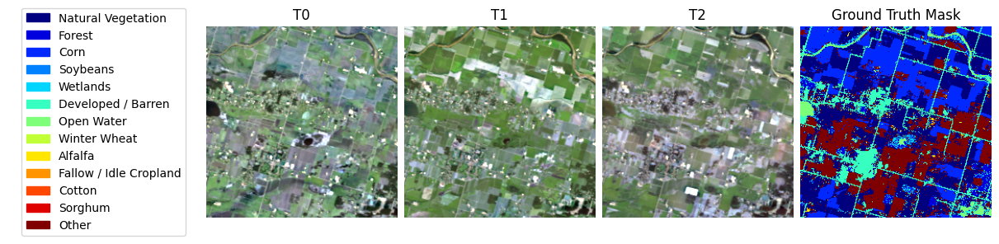

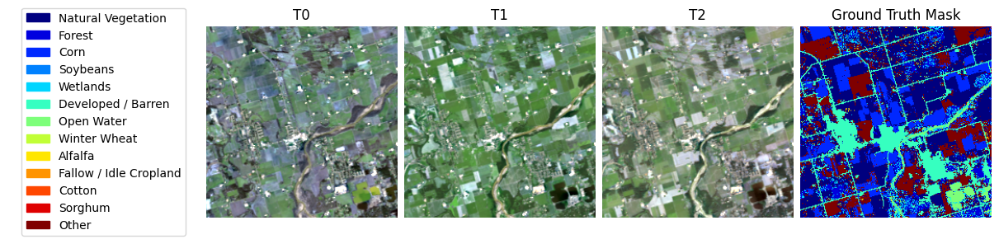

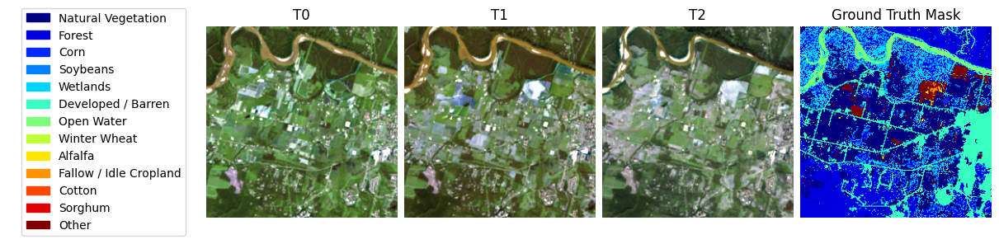

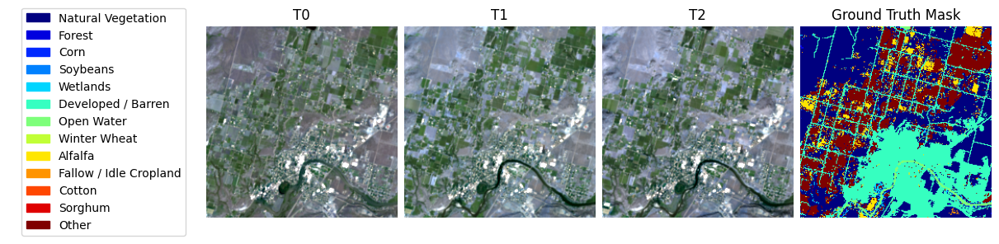

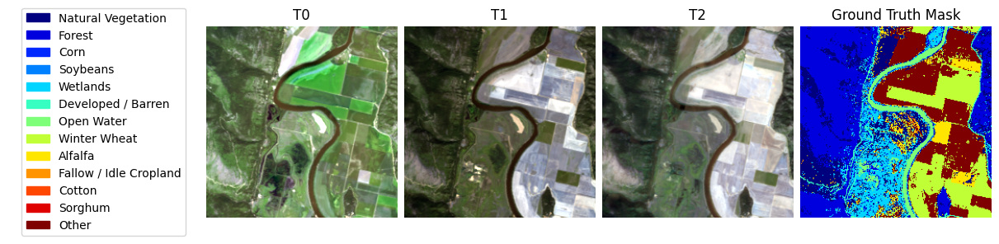

In [36]:
# Ploting a few samples
for i in range(5):
    train_dataset.plot(train_dataset[i])

In [37]:
# Checking validation split size
val_dataset = data_module.val_dataset
len(val_dataset)

771

In [38]:
# Checking test split
data_module.setup("test")
test_dataset = data_module.test_dataset
len(test_dataset)

771

#### Training setup

In [39]:
pl.seed_everything(SEED)

# Logger
logger = TensorBoardLogger(
    save_dir=OUT_DIR,
    name="multicrop_example",
)

# Callbacks
checkpoint_callback = ModelCheckpoint(
    monitor="val/Multiclass_Jaccard_Index",
    mode="max",
    dirpath=os.path.join(OUT_DIR, "multicrop_example", "checkpoints"),
    filename="best-checkpoint-{epoch:02d}-{val_loss:.2f}",
    save_top_k=1,
)

# Trainer
trainer = pl.Trainer(
    accelerator="auto",
    strategy="auto",
    devices="auto",
    precision="bf16-mixed",
    num_nodes=1,
    logger=logger,
    max_epochs=EPOCHS,
    check_val_every_n_epoch=1,
    log_every_n_steps=10,
    enable_checkpointing=True,
    callbacks=[checkpoint_callback],
    limit_predict_batches=1,  # predict only in the first batch for generating plots
)

# DataModule
data_module = MultiTemporalCropClassificationDataModule(
    batch_size=BATCH_SIZE,
    data_root=DATASET_PATH,
    train_transform=train_transforms,
    reduce_zero_label=True,
    expand_temporal_dimension=True,
    num_workers=7,
    use_metadata=True,
)


INFO: Seed set to 0
INFO:lightning.fabric.utilities.seed:Seed set to 0
INFO: Using bfloat16 Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using bfloat16 Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limi

In [3]:
# Model

backbone_args = dict(
    backbone_pretrained=True,
    backbone="prithvi_eo_v2_300_tl", # prithvi_eo_v2_300, prithvi_eo_v2_300_tl, prithvi_eo_v2_600, prithvi_eo_v2_600_tl
    backbone_coords_encoding=["time", "location"],
    backbone_bands=BANDS,
    backbone_num_frames=NUM_FRAMES,
)

decoder_args = dict(
    decoder="UperNetDecoder",
    decoder_channels=256,
    decoder_scale_modules=True,
)

necks = [
    dict(
            name="SelectIndices",
            # indices=[2, 5, 8, 11]    # indices for prithvi_vit_100
            indices=[5, 11, 17, 23],   # indices for prithvi_eo_v2_300
            # indices=[7, 15, 23, 31]  # indices for prithvi_eo_v2_600
        ),
    dict(
            name="ReshapeTokensToImage",
            effective_time_dim=NUM_FRAMES,
        )
    ]

model_args = dict(
    **backbone_args,
    **decoder_args,
    num_classes=len(CLASS_WEIGHTS),
    head_dropout=HEAD_DROPOUT,
    necks=necks,
    rescale=True,
    tiled_inference_config=dict(
        tile_size=256,
        tile_overlap=0.25
    )
)


model = SemanticSegmentationTask(
    model_args=model_args,
    plot_on_val=False,
    class_weights=CLASS_WEIGHTS,
    loss="ce",
    lr=LR,
    optimizer="AdamW",
    optimizer_hparams=dict(weight_decay=WEIGHT_DECAY),
    ignore_index=-1,
    freeze_backbone=FREEZE_BACKBONE,
    freeze_decoder=False,
    model_factory="EncoderDecoderFactory",
    tiled_inference_on_validation=True,
    tiled_inference_on_testing=True,
)

NameError: name 'SemanticSegmentationTask' is not defined

#### Training and testing the model

In [42]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

In [46]:
# Training
trainer.fit(model, datamodule=data_module)

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision bf16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model         │ PixelWiseModel   │  364 M │ train │     0 │
│ 1 │ criterion     │ CrossEntropyLoss │      0 │ train │     0 │
│ 2 │ train_metrics │ MetricCollection │      0 │ train │     0 │
│ 3 │ val_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ test_metrics  │ ModuleList       │      0 │ train │     0 │
└───┴───────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 364 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 364 M                                                                                                
Total estimated model params size (MB): 1.5 K                                                                      
Modules in train mode: 652                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will 
create 7 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller 
than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader 
running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

Exception: You need to define a configuration for the tiled inference.

In [ ]:
ckpt_path = checkpoint_callback.best_model_path

# Test results
test_results = trainer.test(model, datamodule=data_module, ckpt_path=ckpt_path)

In [ ]:
test_results

[{'test/loss': 0.9476954936981201,
  'test/Multiclass_Accuracy': 0.6527066230773926,
  'test/multiclassaccuracy_0': 0.5258018374443054,
  'test/multiclassaccuracy_1': 0.7344022393226624,
  'test/multiclassaccuracy_2': 0.7455450296401978,
  'test/multiclassaccuracy_3': 0.6794723272323608,
  'test/multiclassaccuracy_4': 0.5796242356300354,
  'test/multiclassaccuracy_5': 0.6160429120063782,
  'test/multiclassaccuracy_6': 0.9140505790710449,
  'test/multiclassaccuracy_7': 0.7331819534301758,
  'test/multiclassaccuracy_8': 0.6815562844276428,
  'test/multiclassaccuracy_9': 0.6282399892807007,
  'test/multiclassaccuracy_10': 0.7162940502166748,
  'test/multiclassaccuracy_11': 0.7211771011352539,
  'test/multiclassaccuracy_12': 0.5427747368812561,
  'test/Multiclass_F1_Score': 0.6527066230773926,
  'test/Multiclass_Jaccard_Index': 0.47154152393341064,
  'test/multiclassjaccardindex_0': 0.4495747983455658,
  'test/multiclassjaccardindex_1': 0.5095115900039673,
  'test/multiclassjaccardindex_2'

#### Plot predictions

In [ ]:
# Now we can use the model to generate predictions and visualize results
# As we set limit_predict_batches=1, only the first batch will be used

preds = trainer.predict(model, datamodule=data_module, ckpt_path=ckpt_path)

In [ ]:
# Get first batch of samples for plotting

data_loader = trainer.predict_dataloaders
batch = next(iter(data_loader))

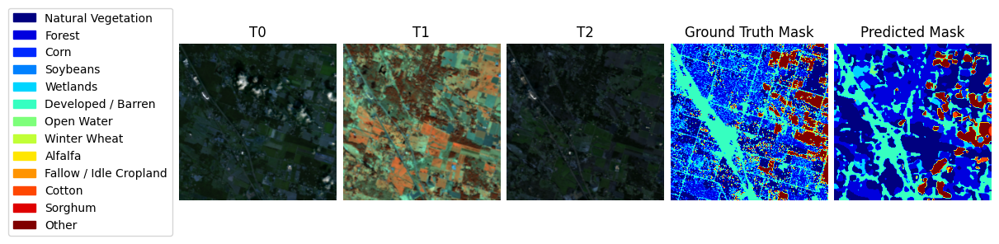

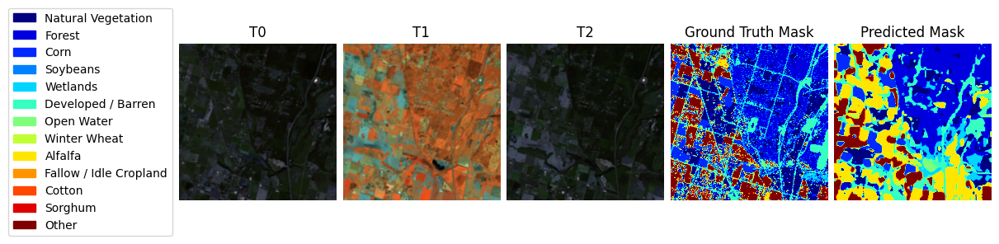

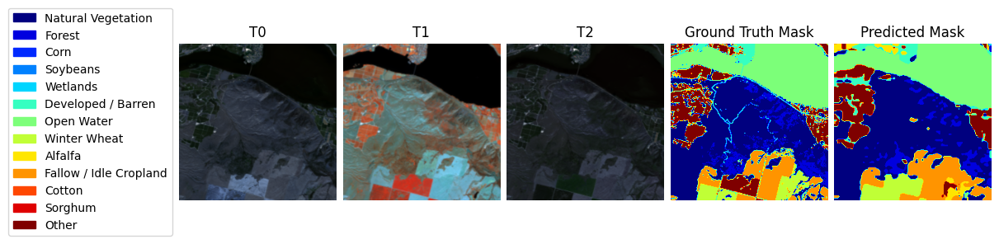

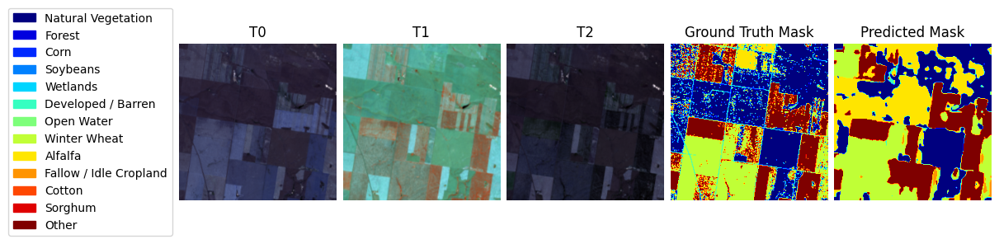

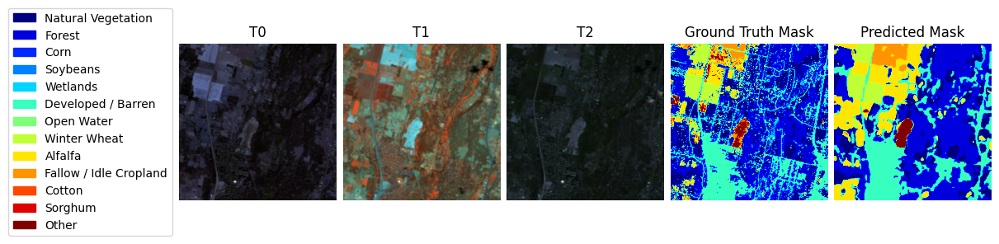

...

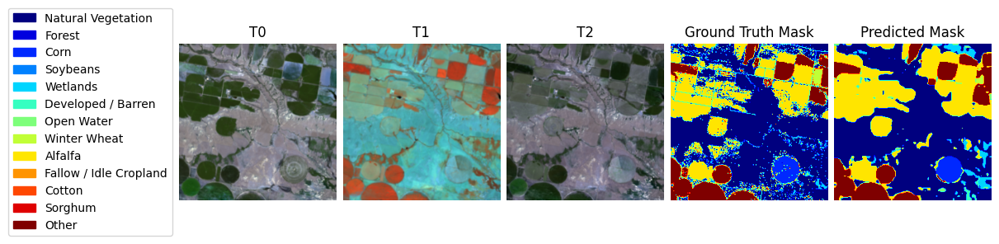

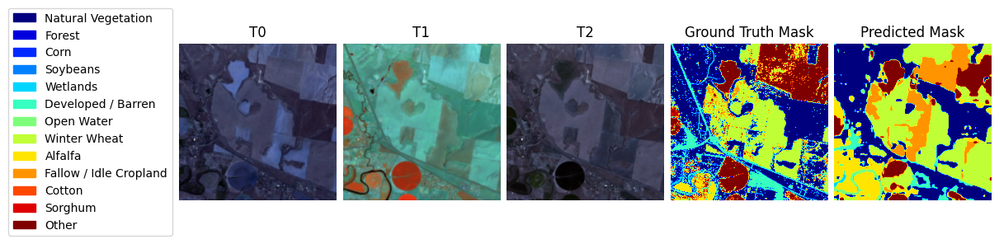

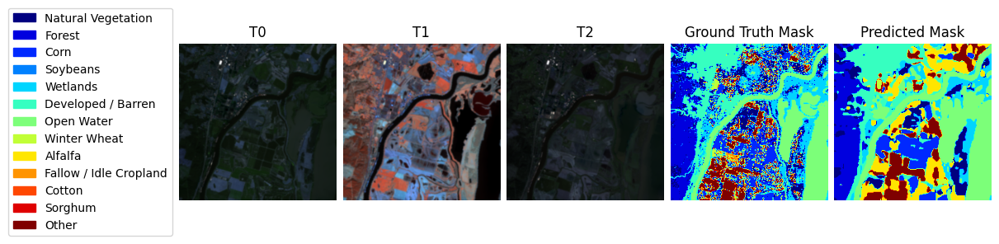

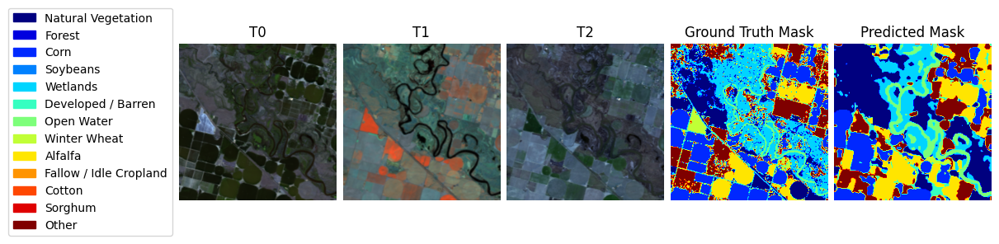

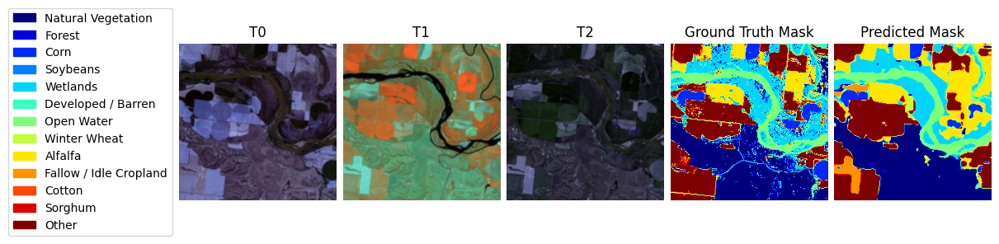

In [ ]:
# Plot samples and respective predictions

for i in range(BATCH_SIZE):

    sample = {key: batch[key][i] for key in batch}
    sample["prediction"] = preds[0][0][i].cpu().numpy()

    data_module.predict_dataset.plot(sample)